# THEMIS Plasma Density ML — v4: Generalization Tests

This notebook implements the "next steps" from v3. One question drives all three
sections: **did the model learn transferable plasma physics, or did it memorise one
day, one orbit geometry, one solar-wind state?** Each section tests that at
increasing strictness:

| Section | Split | What passing means |
|---|---|---|
| 2a | Chronological hold-out (v3 reference) | Model works later the *same day* |
| 2b | **Leave-one-day-out** (event-based) | Model transfers to *unseen days* — different orbit geometry & solar wind |
| 2c | **Leave-one-probe-out** (multi-day) | Model transfers to an *unseen spacecraft* |
| 3 | **Cross-mission: THEMIS → MMS** | Model transfers to a *different mission, instrument suite, and epoch* |

The feature set is the leakage-free one from v3 (scpot, Te, |B|, R, + OMNI solar
wind). For the cross-mission test the features are reduced to the subset measurable
on both missions.

> **Runtime note:** first run downloads several days × 5 THEMIS probes plus one MMS
> day (~a few GB total). PySPEDAS caches everything locally, so re-runs are fast.
> Trim the `DAYS` list to shorten the first run.

---
## 0 — Install & Imports

In [1]:
import sys, subprocess
subprocess.run([sys.executable, '-m', 'pip', 'install', 'pyspedas', 'minisom'], check=True)
print('Install complete — restart the kernel if pyspedas still fails to import.')

Install complete — restart the kernel if pyspedas still fails to import.



[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

import pyspedas
from pyspedas import get_data, tnames

from sklearn.base              import clone
from sklearn.model_selection   import train_test_split, GridSearchCV, TimeSeriesSplit
from sklearn.preprocessing     import StandardScaler
from sklearn.pipeline          import Pipeline
from sklearn.metrics           import r2_score, mean_squared_error, mean_absolute_error
from sklearn.inspection        import permutation_importance
from sklearn.linear_model      import Ridge
from sklearn.ensemble          import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors         import KNeighborsRegressor

RNG   = 42
TSCV  = TimeSeriesSplit(n_splits=5)
RE_KM = 6371.0

def make_pipeline(model):
    return Pipeline([('scaler', StandardScaler()), ('model', model)])

def safe_interp(t_src, y_src, t_ref):
    if t_src is None or y_src is None or len(np.atleast_1d(t_src)) == 0:
        return np.full(len(t_ref), np.nan)
    y = np.asarray(y_src, dtype=float)
    good = np.isfinite(y)
    if good.sum() < 2:
        return np.full(len(t_ref), np.nan)
    return np.interp(t_ref, np.asarray(t_src)[good], y[good],
                     left=np.nan, right=np.nan)

print('Imports OK.')

Imports OK.


---
## 1 — Multi-Day, Multi-Probe THEMIS Data

Days are chosen to span **different orbital configurations and seasons**:

- **2007-07-20** — the v3 day: string-of-pearls configuration (all probes on
  similar orbits, dayside apogee). Probes sample nearly the same regions, which is
  why v3's leave-one-probe-out test was too easy.
- **2008-02-16** — first tail season: orbits placed for magnetotail conjunctions
  (apogees from ~10 to ~30 R_E), probes now sample genuinely different regions.
- **2008-07-16** — dayside season with separated orbits (magnetopause/sheath sampling).
- **2009-02-27** — second tail season, further orbit evolution.

Add or remove days freely — everything downstream adapts. More days = better
statistics for the leave-one-day-out test (each day is one fold).

In [3]:
DAYS = [
    '2007-07-20',   # string-of-pearls (v3 day)
    '2008-02-16',   # tail season 1
    '2008-07-16',   # dayside season, separated orbits
    '2009-02-27',   # tail season 2
]
PROBES   = ['a', 'b', 'c', 'd', 'e']
RESAMPLE = '30s'

def day_trange(day):
    return [f'{day}/00:00:00', f'{day}/23:59:59']

print(f'{len(DAYS)} days × {len(PROBES)} probes')

4 days × 5 probes


In [4]:
# ── THEMIS loader: one probe, one day → DataFrame ─────────────────────────────
def load_themis_probe_day(P, day):
    TR = day_trange(day)
    pyspedas.projects.themis.esa(
        trange=TR, probe=P, level='l2', time_clip=True,
        varnames=[f'th{P}_peer_density', f'th{P}_peir_density',
                  f'th{P}_peer_sc_pot', f'th{P}_peer_avgtemp',
                  f'th{P}_peer_vthermal'])
    pyspedas.projects.themis.fgm(trange=TR, probe=P, level='l2', time_clip=True)
    pyspedas.projects.themis.state(trange=TR, probe=P, time_clip=True)

    ne_d = get_data(f'th{P}_peer_density')
    if ne_d is None:
        return None
    t_ref = ne_d.times
    ne    = np.asarray(ne_d.y, dtype=float)

    def grab(name):
        d = get_data(name)
        return safe_interp(d.times, d.y, t_ref) if d is not None                else np.full_like(ne, np.nan)

    scpot_i = grab(f'th{P}_peer_sc_pot')
    Te_i    = grab(f'th{P}_peer_avgtemp')
    vth_i   = grab(f'th{P}_peer_vthermal')

    try:
        b_d = get_data(f'th{P}_fgs_gsm')
        B_i = safe_interp(b_d.times, np.linalg.norm(b_d.y, axis=1), t_ref)
    except Exception:
        B_i = np.full_like(ne, np.nan)

    X_i = Y_i = Z_i = np.full_like(ne, np.nan)
    try:
        pos_d = get_data(f'th{P}_pos_gsm')
        if pos_d is not None and pos_d.y.ndim == 2:
            X_i = safe_interp(pos_d.times, pos_d.y[:, 0] / RE_KM, t_ref)
            Y_i = safe_interp(pos_d.times, pos_d.y[:, 1] / RE_KM, t_ref)
            Z_i = safe_interp(pos_d.times, pos_d.y[:, 2] / RE_KM, t_ref)
    except Exception:
        pass
    R_i = np.sqrt(X_i**2 + Y_i**2 + Z_i**2)

    d = pd.DataFrame({'time': t_ref, 'ne': ne, 'scpot': scpot_i, 'Te': Te_i,
                      'vth': vth_i, 'B': B_i, 'x_re': X_i, 'y_re': Y_i,
                      'z_re': Z_i, 'R_re': R_i})
    d['dt'] = pd.to_datetime(d['time'], unit='s')
    d = (d.set_index('dt').resample(RESAMPLE).median()
          .dropna(subset=['ne']).reset_index())
    d['probe'], d['day'], d['mission'] = P, day, 'THEMIS'
    d['ne_lag1'] = d['ne'].shift(1)          # persistence baseline only
    d.dropna(subset=['ne', 'scpot', 'Te', 'B'], inplace=True)
    return d.reset_index(drop=True)

In [5]:
# ── OMNI loader: one day → interpolator inputs ────────────────────────────────
OMNI_VARS = {'sw_bz': 'BZ_GSM', 'sw_speed': 'flow_speed',
             'sw_dens': 'proton_density', 'sw_pdyn': 'Pressure',
             'sym_h': 'SYM_H'}

def load_omni_day(day):
    try:
        pyspedas.projects.omni.data(trange=day_trange(day), datatype='1min',
                                    time_clip=True)
        return {k: get_data(v) for k, v in OMNI_VARS.items()}
    except Exception as e:
        print(f'  OMNI failed for {day}: {e}')
        return {k: None for k in OMNI_VARS}

def attach_omni(d, omni):
    t = d['dt'].astype('int64').values / 1e9
    for k, v in omni.items():
        d[k] = safe_interp(v.times, v.y, t) if v is not None else np.nan
    return d

In [6]:
# ── Load everything ───────────────────────────────────────────────────────────
frames = []
for day in DAYS:
    print(f'\n════ {day} ════')
    omni = load_omni_day(day)
    for P in PROBES:
        try:
            d = load_themis_probe_day(P, day)
            if d is None or len(d) < 50:
                print(f'  th{P}: insufficient data — skipped')
                continue
            d = attach_omni(d, omni)
            frames.append(d)
            print(f'  th{P}: {len(d)} pts')
        except Exception as e:
            print(f'  th{P} failed: {e}')

df = pd.concat(frames, ignore_index=True)
df = df[df['ne'] > 0].copy()
df['log_ne'] = np.log10(df['ne'])
df.sort_values('dt', inplace=True)
df.reset_index(drop=True, inplace=True)

print(f'\nCombined: {df.shape[0]} pts')
print(df.groupby(['day', 'probe']).size().unstack(fill_value=0))

18-Jul-26 15:15:52: Downloading remote index: https://spdf.gsfc.nasa.gov/pub/data/omni/omni_cdaweb/hro_1min/2007/



════ 2007-07-20 ════


18-Jul-26 15:15:54: File is current: /Users/admin-victor/spedas_data/omni/hro_1min/2007/omni_hro_1min_20070701_v01.cdf
18-Jul-26 15:15:54: Downloading remote index: https://themis.ssl.berkeley.edu/data/themis/tha/l2/esa/2007/
18-Jul-26 15:16:05: Retrying (Retry(total=2, connect=None, read=None, redirect=None, status=None)) after connection broken by 'ConnectTimeoutError(<HTTPSConnection(host='themis.ssl.berkeley.edu', port=443) at 0x15dbf9310>, 'Connection to themis.ssl.berkeley.edu timed out. (connect timeout=10)')': /data/themis/tha/l2/esa/2007/
18-Jul-26 15:16:08: Remote index took 13.3 seconds to return, may indicate problems on remote server (index_slow)
18-Jul-26 15:16:09: Retrying (Retry(total=2, connect=None, read=None, redirect=None, status=None)) after connection broken by 'ConnectionResetError(54, 'Connection reset by peer')': /data/themis/tha/l2/esa/2007/tha_l2_esa_20070720_v01.cdf
18-Jul-26 15:16:23: Retrying (Retry(total=1, connect=None, read=None, redirect=None, status=N

  tha: 2846 pts


18-Jul-26 15:19:00: Remote index took 5.9 seconds to return, may indicate problems on remote server (index_slow)
18-Jul-26 15:19:08: Retrying (Retry(total=2, connect=None, read=None, redirect=None, status=None)) after connection broken by 'ConnectionResetError(54, 'Connection reset by peer')': /data/themis/thb/l2/esa/2007/thb_l2_esa_20070720_v01.cdf
18-Jul-26 15:19:12: Retrying (Retry(total=1, connect=None, read=None, redirect=None, status=None)) after connection broken by 'ConnectionResetError(54, 'Connection reset by peer')': /data/themis/thb/l2/esa/2007/thb_l2_esa_20070720_v01.cdf
18-Jul-26 15:19:22: Retrying (Retry(total=0, connect=None, read=None, redirect=None, status=None)) after connection broken by 'ConnectionResetError(54, 'Connection reset by peer')': /data/themis/thb/l2/esa/2007/thb_l2_esa_20070720_v01.cdf
18-Jul-26 15:19:28: File is current: /Users/admin-victor/spedas_data/themis/thb/l2/esa/2007/thb_l2_esa_20070720_v01.cdf
18-Jul-26 15:19:28: Downloading remote index: http

  thb: insufficient data — skipped


... (32 outputs left out)

18-Jul-26 18:43:32: Downloading https://themis.ssl.berkeley.edu/data/themis/thd/l2/esa/2009/thd_l2_esa_20090227_v01.cdf to /Users/admin-victor/spedas_data/themis/thd/l2/esa/2009/thd_l2_esa_20090227_v01.cdf
18-Jul-26 19:01:29: Downloading remote index: https://themis.ssl.berkeley.edu/data/themis/the/l2/esa/2009/


  thd failed: HTTPSConnectionPool(host='themis.ssl.berkeley.edu', port=443): Read timed out.


18-Jul-26 19:01:31: Downloading https://themis.ssl.berkeley.edu/data/themis/the/l2/esa/2009/the_l2_esa_20090227_v01.cdf to /Users/admin-victor/spedas_data/themis/the/l2/esa/2009/the_l2_esa_20090227_v01.cdf
18-Jul-26 19:01:33: Download of /Users/admin-victor/spedas_data/themis/the/l2/esa/2009/the_l2_esa_20090227_v01.cdf complete, 16.135 MB in 2.4 sec (6.857 MB/sec) (transfer_normal)
18-Jul-26 19:01:33: Downloading remote index: https://themis.ssl.berkeley.edu/data/themis/the/l2/fgm/2009/
18-Jul-26 19:01:35: Downloading https://themis.ssl.berkeley.edu/data/themis/the/l2/fgm/2009/the_l2_fgm_20090227_v01.cdf to /Users/admin-victor/spedas_data/themis/the/l2/fgm/2009/the_l2_fgm_20090227_v01.cdf
18-Jul-26 19:01:38: Download of /Users/admin-victor/spedas_data/themis/the/l2/fgm/2009/the_l2_fgm_20090227_v01.cdf complete, 29.790 MB in 2.8 sec (10.767 MB/sec) (transfer_normal)
18-Jul-26 19:01:38: Downloading https://themis.ssl.berkeley.edu/data/themis/the/l1/state/2009/the_l1_state_20090227.cdf to

  the: 2864 pts

Combined: 28748 pts
probe          a    b     c     d     e
day                                    
2007-07-20  2846    0  2827     0     0
2008-02-16     0  186  2858  2861  2864
2008-07-16  2856    0     0  2865  2858
2009-02-27  2863    0     0     0  2864


18-Jul-26 19:01:39: /opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/matplotlib/transforms.py:195: ResourceWarning: unclosed file <_io.FileIO name='/var/folders/1c/p47qnnc123xd86gmn5km5bcm0000gn/T/tmpv8dqkwnhcdf' mode='rb+' closefd=True>
  ref = weakref.ref(

18-Jul-26 19:01:39: /opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/tempfile.py:484: ResourceWarning: Implicitly cleaning up <_TemporaryFileWrapper file=<_io.BufferedRandom name='/var/folders/1c/p47qnnc123xd86gmn5km5bcm0000gn/T/tmpv8dqkwnhcdf'>>
  _warnings.warn(self.warn_message, ResourceWarning)

18-Jul-26 19:01:39: /opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/matplotlib/transforms.py:195: ResourceWarning: unclosed file <_io.FileIO name='/var/folders/1c/p47qnnc123xd86gmn5km5bcm0000gn/T/tmp853b47g8cdf' mode='rb+' closefd=True>
  ref = weakref.ref(

18-Jul-26 19:01:39: /opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/tempfile.py:484: ResourceWarning: Implicitly cleaning 

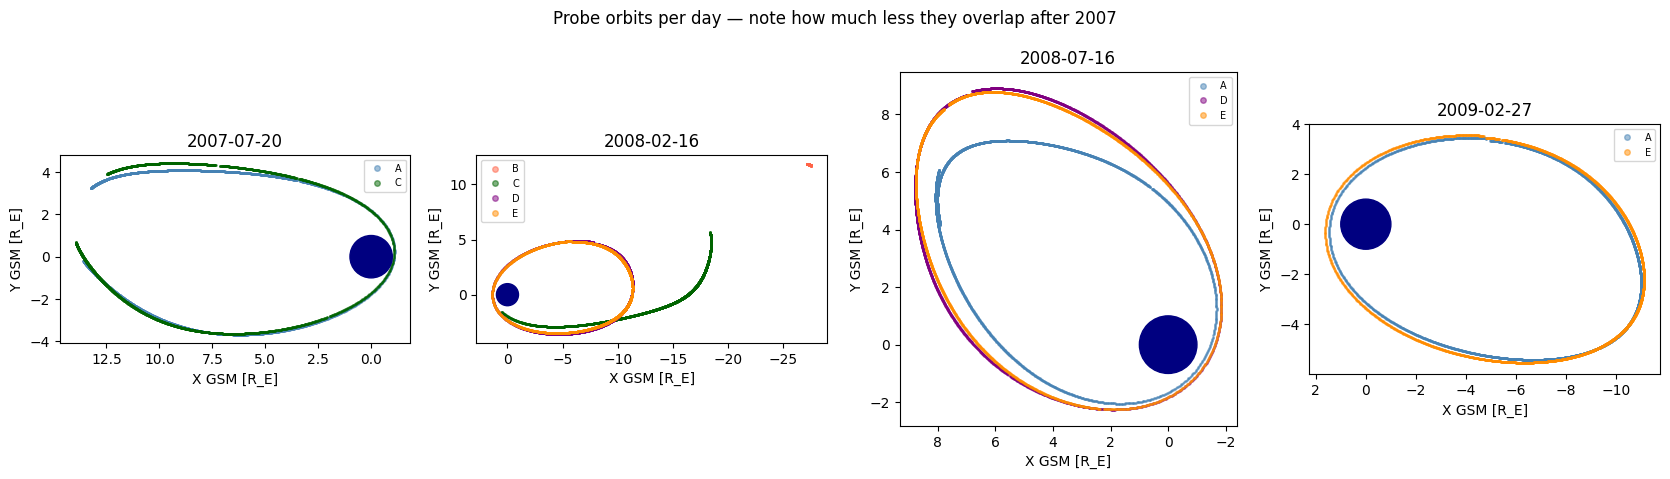

In [7]:
# ── Where were the probes each day? (orbit context for the splits) ────────────
n_days = df['day'].nunique()
fig, axes = plt.subplots(1, n_days, figsize=(4.2*n_days, 4.4))
if n_days == 1:
    axes = [axes]
colors = {'a':'steelblue','b':'tomato','c':'darkgreen','d':'purple','e':'darkorange'}
for ax, day in zip(axes, sorted(df['day'].unique())):
    sub = df[df['day'] == day]
    for p in sorted(sub['probe'].unique()):
        s = sub[sub['probe'] == p]
        ax.plot(s['x_re'], s['y_re'], '.', ms=2, alpha=0.5,
                color=colors.get(p, 'gray'), label=p.upper())
    ax.add_patch(plt.Circle((0, 0), 1, color='navy', zorder=5))
    ax.set_title(day); ax.set_xlabel('X GSM [R_E]'); ax.set_ylabel('Y GSM [R_E]')
    ax.invert_xaxis(); ax.set_aspect('equal'); ax.legend(fontsize=7, markerscale=4)
plt.suptitle('Probe orbits per day — note how much less they overlap after 2007',
             y=1.03)
plt.tight_layout(); plt.show()

In [8]:
# ── Feature set (leakage-free, from v3) ───────────────────────────────────────
PHYS_FEATURES = ['scpot', 'Te', 'vth', 'B', 'R_re']
for f in OMNI_VARS:
    if df[f].notna().sum() > 500:
        PHYS_FEATURES.append(f)
print(f'Features ({len(PHYS_FEATURES)}): {PHYS_FEATURES}')
print(f'Target: log10(ne)  |  {df["log_ne"].min():.2f} … {df["log_ne"].max():.2f}')

Features (10): ['scpot', 'Te', 'vth', 'B', 'R_re', 'sw_bz', 'sw_speed', 'sw_dens', 'sw_pdyn', 'sym_h']
Target: log10(ne)  |  -4.77 … 1.68


---
## 2 — Three Generalization Tests, One Model

A single model family is tuned once on a chronological split (2a), then the *same
hyperparameters* are re-fit inside each leave-one-out fold (2b, 2c). That keeps the
comparison clean: any score drop is due to the split, not to different tuning.

In [9]:
# ── 2a: Reference — chronological hold-out with tuning ────────────────────────
valid = df[PHYS_FEATURES + ['log_ne', 'ne', 'ne_lag1', 'day', 'probe']].dropna(
    subset=PHYS_FEATURES + ['log_ne']).reset_index(drop=True)
X_all = valid[PHYS_FEATURES].values
y_all = valid['log_ne'].values

X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.30,
                                          shuffle=False)

candidates = {
    'Ridge': (make_pipeline(Ridge()),
              {'model__alpha': [0.1, 1.0, 10.0, 100.0]}),
    'kNN':   (make_pipeline(KNeighborsRegressor()),
              {'model__n_neighbors': [5, 10, 20],
               'model__weights': ['uniform', 'distance']}),
    'Random Forest': (make_pipeline(RandomForestRegressor(random_state=RNG, n_jobs=-1)),
              {'model__n_estimators': [200], 'model__max_depth': [None, 10],
               'model__max_features': ['sqrt']}),
    'Gradient Boosting': (make_pipeline(GradientBoostingRegressor(random_state=RNG)),
              {'model__n_estimators': [200], 'model__learning_rate': [0.05, 0.1],
               'model__max_depth': [3, 5]}),
}

chrono_rows, best_est, best_name, best_r2 = [], None, None, -np.inf
for name, (pipe, grid) in candidates.items():
    gs = GridSearchCV(pipe, grid, cv=TSCV, scoring='r2', n_jobs=-1, refit=True)
    gs.fit(X_tr, y_tr)
    yp = gs.predict(X_te)
    r2 = r2_score(y_te, yp)
    chrono_rows.append({'Model': name, 'R²': round(r2, 4),
                        'RMSE (dex)': round(np.sqrt(mean_squared_error(y_te, yp)), 4)})
    print(f'{name:<20} R²={r2:.4f}')
    if r2 > best_r2:
        best_r2, best_name, best_est = r2, name, gs.best_estimator_

# Persistence baseline on the same test span
lag, tgt = valid['ne_lag1'].values, valid['ne'].values
n_te = len(y_te)
m = (np.isfinite(lag[-n_te:]) & (lag[-n_te:] > 0) &
     np.isfinite(tgt[-n_te:]) & (tgt[-n_te:] > 0))
pers_r2 = r2_score(np.log10(tgt[-n_te:][m]), np.log10(lag[-n_te:][m]))

chrono_df = pd.DataFrame(chrono_rows).sort_values('R²', ascending=False)
print('\n' + chrono_df.to_string(index=False))
print(f'\nPersistence baseline R² = {pers_r2:.4f}')
print(f'→ Reference model: {best_name} (chronological R² = {best_r2:.4f})')

/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs

Ridge                R²=-0.0223


/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs

kNN                  R²=0.4002


/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs

Random Forest        R²=0.6808


/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/envs

Gradient Boosting    R²=0.6033

            Model      R²  RMSE (dex)
    Random Forest  0.6808      0.2149
Gradient Boosting  0.6033      0.2395
              kNN  0.4002      0.2945
            Ridge -0.0223      0.3845

Persistence baseline R² = 0.9531
→ Reference model: Random Forest (chronological R² = 0.6808)


In [10]:
# ── 2b: Leave-one-day-out (event-based split) ─────────────────────────────────
lodo_rows = []
for held_day in sorted(valid['day'].unique()):
    tr = valid[valid['day'] != held_day]
    te = valid[valid['day'] == held_day]
    if len(te) < 100:
        continue
    mdl = clone(best_est)
    mdl.fit(tr[PHYS_FEATURES].values, tr['log_ne'].values)
    yp = mdl.predict(te[PHYS_FEATURES].values)
    lodo_rows.append({'Held-out day': held_day,
                      'Train pts': len(tr), 'Test pts': len(te),
                      'R²': round(r2_score(te['log_ne'], yp), 4),
                      'RMSE (dex)': round(np.sqrt(mean_squared_error(te['log_ne'], yp)), 4)})

lodo_df = pd.DataFrame(lodo_rows)
print(f'Leave-one-day-out — {best_name}\n')
print(lodo_df.to_string(index=False))
print(f'\nMean R² = {lodo_df["R²"].mean():.4f}   '
      f'(chronological reference: {best_r2:.4f})')
print('Low or negative R² on a held-out day means that day\'s orbit geometry /')
print('solar-wind state was genuinely outside the training distribution.')

18-Jul-26 19:06:10: /opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(

18-Jul-26 19:06:10: /opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(

18-Jul-26 19:06:10: /opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thre

Leave-one-day-out — Random Forest

Held-out day  Train pts  Test pts      R²  RMSE (dex)
  2007-07-20      23016      5643 -0.7197      0.9465
  2008-02-16      19934      8725 -0.2431      0.4657
  2008-07-16      20089      8570  0.4324      0.2855
  2009-02-27      22938      5721  0.5784      0.2367

Mean R² = 0.0120   (chronological reference: 0.6808)
Low or negative R² on a held-out day means that day's orbit geometry /
solar-wind state was genuinely outside the training distribution.


In [11]:
# ── 2c: Leave-one-probe-out (now on multi-day data) ───────────────────────────
lopo_rows = []
for held_probe in sorted(valid['probe'].unique()):
    tr = valid[valid['probe'] != held_probe]
    te = valid[valid['probe'] == held_probe]
    if len(te) < 100:
        continue
    mdl = clone(best_est)
    mdl.fit(tr[PHYS_FEATURES].values, tr['log_ne'].values)
    yp = mdl.predict(te[PHYS_FEATURES].values)
    lopo_rows.append({'Held-out probe': held_probe.upper(),
                      'Train pts': len(tr), 'Test pts': len(te),
                      'R²': round(r2_score(te['log_ne'], yp), 4),
                      'RMSE (dex)': round(np.sqrt(mean_squared_error(te['log_ne'], yp)), 4)})

lopo_df = pd.DataFrame(lopo_rows)
print(f'Leave-one-probe-out — {best_name}\n')
print(lopo_df.to_string(index=False))
print(f'\nMean R² = {lopo_df["R²"].mean():.4f}')
print('With tail-season days included, probes B and C (larger apogees) sample')
print('regions the inner probes never visit — expect them to be the hard folds.')

18-Jul-26 19:06:47: /opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(

18-Jul-26 19:06:47: /opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(

18-Jul-26 19:06:48: /opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thre

Leave-one-probe-out — Random Forest

Held-out probe  Train pts  Test pts      R²  RMSE (dex)
             A      20115      8544  0.7995      0.2975
             B      28484       175 -3.2162      0.2251
             C      23000      5659  0.8351      0.4149
             D      22947      5712  0.8307      0.1455
             E      20090      8569  0.8905      0.1254

Mean R² = 0.0279
With tail-season days included, probes B and C (larger apogees) sample
regions the inner probes never visit — expect them to be the hard folds.


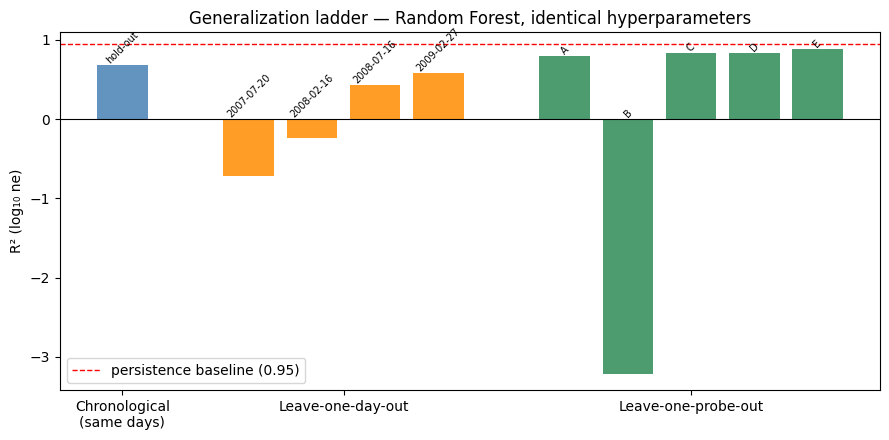

In [12]:
# ── Comparison chart: same model, three splits ────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 4.5))
groups = [
    ('Chronological\n(same days)', [best_r2], ['hold-out']),
    ('Leave-one-day-out', lodo_df['R²'].tolist(), lodo_df['Held-out day'].tolist()),
    ('Leave-one-probe-out', lopo_df['R²'].tolist(), lopo_df['Held-out probe'].tolist()),
]
xpos, xticks, xlabels = 0, [], []
palette = ['steelblue', 'darkorange', 'seagreen']
for (gname, vals, labels), color in zip(groups, palette):
    xs = np.arange(xpos, xpos + len(vals))
    ax.bar(xs, vals, color=color, alpha=0.85)
    for x, v, l in zip(xs, vals, labels):
        ax.text(x, max(v, 0) + 0.02, l, ha='center', fontsize=7, rotation=45)
    xticks.append(xs.mean()); xlabels.append(gname)
    xpos += len(vals) + 1
ax.axhline(pers_r2, color='red', ls='--', lw=1,
           label=f'persistence baseline ({pers_r2:.2f})')
ax.axhline(0, color='k', lw=0.8)
ax.set_xticks(xticks); ax.set_xticklabels(xlabels)
ax.set_ylabel('R² (log₁₀ ne)')
ax.set_title(f'Generalization ladder — {best_name}, identical hyperparameters')
ax.legend()
plt.tight_layout(); plt.show()

---
## 3 — Cross-Mission Validation: THEMIS → MMS

The strictest test: train on **all THEMIS data**, predict electron density measured
by a **different mission** (MMS-1, launched 2015 — different plasma instrument
(FPI/DES vs ESA), different potential probe (EDP vs EFI), different epoch of the
solar cycle).

**Shared features only.** THEMIS `vth` has no directly loaded MMS twin here, so the
cross-mission feature set is: `scpot`, `Te`, `|B|`, `R_re` + OMNI (solar-wind data
is mission-independent). MMS DES provides T∥ and T⊥ separately; the scalar
temperature is `(T∥ + 2T⊥)/3`.

**Expect degradation — and interpret it.** Spacecraft potential calibration differs
between missions (different probe geometry, photoemission, ASPOC on MMS), so some
domain shift is physical, not a bug. The interesting question is whether the model
still ranks densities correctly (high R² in log space) despite offsets.

In [13]:
# ── Load one MMS day ──────────────────────────────────────────────────────────
MMS_DAY   = '2017-07-20'      # tail season for MMS — overlaps THEMIS regions
MMS_PROBE = '1'
TR_MMS    = day_trange(MMS_DAY)

mms_df = None
try:
    pyspedas.projects.mms.fpi(trange=TR_MMS, probe=MMS_PROBE,
                              datatype='des-moms', data_rate='fast',
                              time_clip=True)
    pyspedas.projects.mms.edp(trange=TR_MMS, probe=MMS_PROBE,
                              datatype='scpot', data_rate='fast',
                              time_clip=True)
    pyspedas.projects.mms.fgm(trange=TR_MMS, probe=MMS_PROBE, time_clip=True)
    pyspedas.projects.mms.mec(trange=TR_MMS, probe=MMS_PROBE, time_clip=True)

    pre = f'mms{MMS_PROBE}'
    ne_d = get_data(f'{pre}_des_numberdensity_fast')
    if ne_d is None:
        raise RuntimeError('no DES density; tnames(): ' + str(tnames(f'{pre}_des*')))
    t_ref = ne_d.times
    ne    = np.asarray(ne_d.y, dtype=float)

    def grab_mms(name):
        d = get_data(name)
        return safe_interp(d.times, d.y, t_ref) if d is not None                else np.full_like(ne, np.nan)

    tpar  = grab_mms(f'{pre}_des_temppara_fast')
    tperp = grab_mms(f'{pre}_des_tempperp_fast')
    Te_i  = (tpar + 2*tperp) / 3.0                     # scalar Te [eV]

    sc = get_data(f'{pre}_edp_scpot_fast_l2')
    if sc is None:                                     # name fallback
        cands = tnames(f'{pre}_edp_scpot*')
        sc = get_data(cands[0]) if cands else None
    scpot_i = safe_interp(sc.times, sc.y, t_ref) if sc is not None               else np.full_like(ne, np.nan)

    b = get_data(f'{pre}_fgm_b_gsm_srvy_l2')           # Nx4, col 3 = |B|
    B_i = safe_interp(b.times, b.y[:, 3], t_ref) if b is not None           else np.full_like(ne, np.nan)

    pos = get_data(f'{pre}_mec_r_gsm')                 # km
    if pos is not None:
        R_i = safe_interp(pos.times, np.linalg.norm(pos.y, axis=1)/RE_KM, t_ref)
        X_i = safe_interp(pos.times, pos.y[:, 0]/RE_KM, t_ref)
        Y_i = safe_interp(pos.times, pos.y[:, 1]/RE_KM, t_ref)
    else:
        R_i = X_i = Y_i = np.full_like(ne, np.nan)

    mms_df = pd.DataFrame({'time': t_ref, 'ne': ne, 'scpot': scpot_i,
                           'Te': Te_i, 'B': B_i, 'R_re': R_i,
                           'x_re': X_i, 'y_re': Y_i})
    mms_df['dt'] = pd.to_datetime(mms_df['time'], unit='s')
    mms_df = (mms_df.set_index('dt').resample(RESAMPLE).median()
                    .dropna(subset=['ne']).reset_index())
    mms_df = attach_omni(mms_df, load_omni_day(MMS_DAY))
    mms_df = mms_df[mms_df['ne'] > 0].copy()
    mms_df['log_ne'] = np.log10(mms_df['ne'])
    print(f'MMS-{MMS_PROBE} {MMS_DAY}: {len(mms_df)} pts after resampling')
except Exception as e:
    print(f'MMS load failed: {e}')
    print('Loaded MMS variables:', tnames('mms*')[:20] if tnames('mms*') else 'none')

23-Jul-26 00:39:34: /opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/pyspedas/projects/mms/mms_login_lasp.py:79: ResourceWarning: unclosed file <_io.BufferedWriter name='/Users/admin-victor/mms_auth_info.pkl'>
  saved_auth = pickle.dump(

23-Jul-26 00:39:36: Downloading mms1_fpi_fast_l2_des-moms_20170720000000_v3.4.0.cdf to /Users/admin-victor/spedas_data/mms/mms1/fpi/fast/l2/des-moms/2017/07
23-Jul-26 00:39:37: Downloading mms1_fpi_fast_l2_des-moms_20170720020000_v3.4.0.cdf to /Users/admin-victor/spedas_data/mms/mms1/fpi/fast/l2/des-moms/2017/07
23-Jul-26 00:39:37: Downloading mms1_fpi_fast_l2_des-moms_20170720040000_v3.4.0.cdf to /Users/admin-victor/spedas_data/mms/mms1/fpi/fast/l2/des-moms/2017/07
23-Jul-26 00:39:38: Downloading mms1_fpi_fast_l2_des-moms_20170720060000_v3.4.0.cdf to /Users/admin-victor/spedas_data/mms/mms1/fpi/fast/l2/des-moms/2017/07
23-Jul-26 00:39:38: Downloading mms1_fpi_fast_l2_des-moms_20170720080000_v3.4.0.cdf to /Users/admin-victor/speda

MMS-1 2017-07-20: 2753 pts after resampling


In [14]:
# ── Train on all THEMIS, test on MMS ──────────────────────────────────────────
if mms_df is not None and len(mms_df) > 100:
    XMISSION_FEATURES = [f for f in ['scpot', 'Te', 'B', 'R_re',
                                     'sw_bz', 'sw_speed', 'sw_dens',
                                     'sw_pdyn', 'sym_h']
                         if f in PHYS_FEATURES or f in ['scpot', 'Te', 'B', 'R_re']]
    XMISSION_FEATURES = [f for f in XMISSION_FEATURES
                         if mms_df[f].notna().sum() > 100]
    print(f'Cross-mission features: {XMISSION_FEATURES}')

    them_v = valid.dropna(subset=XMISSION_FEATURES)
    mms_v  = mms_df[XMISSION_FEATURES + ['log_ne']].dropna()

    mdl = clone(best_est)
    mdl.fit(them_v[XMISSION_FEATURES].values, them_v['log_ne'].values)
    yp_mms = mdl.predict(mms_v[XMISSION_FEATURES].values)

    r2_x   = r2_score(mms_v['log_ne'], yp_mms)
    rmse_x = np.sqrt(mean_squared_error(mms_v['log_ne'], yp_mms))
    bias_x = np.mean(yp_mms - mms_v['log_ne'])
    corr_x = np.corrcoef(yp_mms, mms_v['log_ne'])[0, 1]

    print(f'\nTHEMIS → MMS-{MMS_PROBE} ({MMS_DAY}), model: {best_name}')
    print(f'  R²          = {r2_x:.4f}')
    print(f'  RMSE        = {rmse_x:.4f} dex')
    print(f'  Mean bias   = {bias_x:+.4f} dex '
          f'(systematic offset — calibration/domain shift)')
    print(f'  Pearson r   = {corr_x:.4f} '
          f'(ranking quality, insensitive to offset)')
    print(f'\n  Bias-corrected R² = '
          f'{r2_score(mms_v["log_ne"], yp_mms - bias_x):.4f}')
    print('  If bias-corrected R² >> raw R², the model transferred the *physics*')
    print('  but not the *calibration* — a constant scpot offset between missions.')
else:
    print('Skipping cross-mission test — MMS data unavailable.')

23-Jul-26 00:40:06: /opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(

23-Jul-26 00:40:06: /opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(

23-Jul-26 00:40:06: /opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thre

Cross-mission features: ['scpot', 'Te', 'B', 'R_re', 'sw_bz', 'sw_speed', 'sw_dens', 'sw_pdyn', 'sym_h']


23-Jul-26 00:40:06: /opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(

23-Jul-26 00:40:06: /opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(

23-Jul-26 00:40:06: /opt/anaconda3/envs/pyspedas_conda_py312/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thre


THEMIS → MMS-1 (2017-07-20), model: Random Forest
  R²          = -1.5511
  RMSE        = 0.6427 dex
  Mean bias   = +0.5388 dex (systematic offset — calibration/domain shift)
  Pearson r   = 0.6767 (ranking quality, insensitive to offset)

  Bias-corrected R² = 0.2418
  If bias-corrected R² >> raw R², the model transferred the *physics*
  but not the *calibration* — a constant scpot offset between missions.


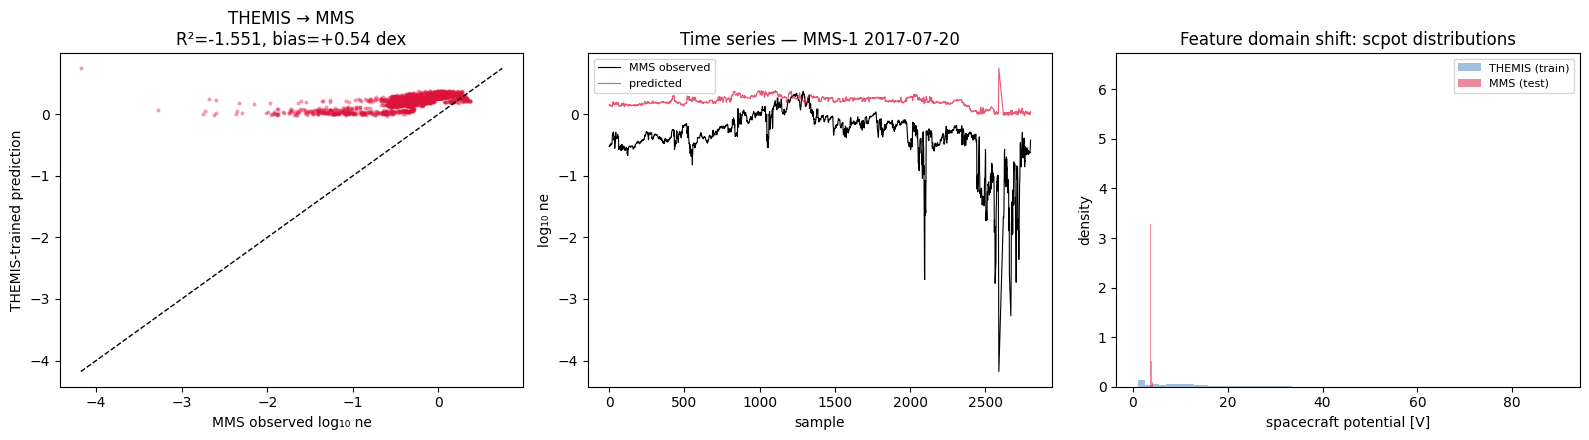

In [15]:
# ── Cross-mission diagnostic plots ────────────────────────────────────────────
if mms_df is not None and len(mms_df) > 100:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

    ax = axes[0]
    ax.scatter(mms_v['log_ne'], yp_mms, s=4, alpha=0.3, color='crimson')
    lims = [min(mms_v['log_ne'].min(), yp_mms.min()),
            max(mms_v['log_ne'].max(), yp_mms.max())]
    ax.plot(lims, lims, 'k--', lw=1)
    ax.set_xlabel('MMS observed log₁₀ ne')
    ax.set_ylabel('THEMIS-trained prediction')
    ax.set_title(f'THEMIS → MMS\nR²={r2_x:.3f}, bias={bias_x:+.2f} dex')

    ax = axes[1]
    ax.plot(mms_v.index, mms_v['log_ne'].values, lw=0.8, color='k',
            label='MMS observed')
    ax.plot(mms_v.index, yp_mms, lw=0.8, color='crimson', alpha=0.7,
            label='predicted')
    ax.set_xlabel('sample'); ax.set_ylabel('log₁₀ ne')
    ax.set_title(f'Time series — MMS-{MMS_PROBE} {MMS_DAY}')
    ax.legend(fontsize=8)

    ax = axes[2]
    for name_, frame, c in [('THEMIS (train)', them_v, 'steelblue'),
                            ('MMS (test)', mms_v, 'crimson')]:
        ax.hist(frame['scpot'], bins=60, density=True, alpha=0.5,
                color=c, label=name_)
    ax.set_xlabel('spacecraft potential [V]'); ax.set_ylabel('density')
    ax.set_title('Feature domain shift: scpot distributions')
    ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

---
## 4 — Summary

In [16]:
rows = [
    {'Test': 'Chronological hold-out (same days)',
     'R²': round(best_r2, 4), 'Notes': best_name},
    {'Test': 'Persistence baseline', 'R²': round(pers_r2, 4),
     'Notes': 'previous 30-s value'},
    {'Test': 'Leave-one-day-out (mean)', 'R²': round(lodo_df['R²'].mean(), 4),
     'Notes': f"worst day: {lodo_df.loc[lodo_df['R²'].idxmin(), 'Held-out day']}"
              f" ({lodo_df['R²'].min():.3f})"},
    {'Test': 'Leave-one-probe-out (mean)', 'R²': round(lopo_df['R²'].mean(), 4),
     'Notes': f"worst probe: {lopo_df.loc[lopo_df['R²'].idxmin(), 'Held-out probe']}"
              f" ({lopo_df['R²'].min():.3f})"},
]
if mms_df is not None and len(mms_df) > 100:
    rows.append({'Test': 'Cross-mission (THEMIS → MMS)', 'R²': round(r2_x, 4),
                 'Notes': f'bias {bias_x:+.2f} dex; '
                          f'bias-corrected R² = '
                          f'{r2_score(mms_v["log_ne"], yp_mms - bias_x):.3f}'})
print(pd.DataFrame(rows).to_string(index=False))

                              Test      R²                                     Notes
Chronological hold-out (same days)  0.6808                             Random Forest
              Persistence baseline  0.9531                       previous 30-s value
          Leave-one-day-out (mean)  0.0120            worst day: 2007-07-20 (-0.720)
        Leave-one-probe-out (mean)  0.0279                   worst probe: B (-3.216)
      Cross-mission (THEMIS → MMS) -1.5511 bias +0.54 dex; bias-corrected R² = 0.242


**How to read the ladder**

- A steady decline (chronological > day-out > probe-out > cross-mission) with all
  rungs above the persistence baseline is the signature of a model that learned
  real but partially domain-specific physics.
- If leave-one-day-out collapses, the model depends on the day's solar-wind state —
  try lagged OMNI features (30–60 min propagation) or more training days.
- If cross-mission shows a large *bias* but strong *correlation*, the physics
  transferred and the residual is inter-calibration (scpot offsets). That's a
  publishable observation in itself: it quantifies how instrument calibration
  limits cross-mission ML.

**Further ideas**

- More MMS days (dayside season, e.g. Jan–Mar, samples magnetopause/sheath).
- Cluster mission via `pyspedas.projects.cluster` for a third mission point.
- Fine-tuning experiment: after training on THEMIS, refit only the final trees /
  a linear output correction on 10% of MMS data — does a tiny calibration sample
  close the gap?